## Import Libraries

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx # Core library for network analysis

import warnings # Suppress non-critical warnings
import collections # defaultdict for community mapping

# Community detection algorithms
from community import community_louvain

# Label Propagation - structural community detection
from networkx.algorithms.community import (label_propagation_communities, girvan_newman, modularity)

warnings.filterwarnings('ignore')
RANDOM_STATE = 42

## Load Data

In [40]:
# Load the Facebook Edge List
FB_PATH = 'facebook_combined.txt'

# Load graph from edge list (each line is 'source_node target_node')
G = nx.read_edgelist(FB_PATH, nodetype=int)

# Remove self-loops as they are not meaningful in a friendship network
G.remove_edges_from(nx.selfloop_edges(G))

print(f'Nodes: {G.number_of_nodes():,}')
print(f'Edges: {G.number_of_edges():,}')
print(f'Connected: {nx.is_connected(G)}')

Nodes: 4,039
Edges: 88,234
Connected: True


##
## Task 1: Network Construction and Basic Characteristics
Basic network statistics are computed: nodes, edges, density, average degree, clustering coefficient, average shortest path length, and diameter. Degree distribution is plotted on a log-log scale. Five node centrality measures are calculated and top nodes identified for each.

**Basic Network Statistics**

In [41]:
"""
 This section computes key structural properties of the graph (G) to understand:
 - Size and connectivity
 - Node importance (degree)
 - Clustering behaviour
 - Network efficiency (path lengths)
"""

# Basic graph size and density
n_nodes  = G.number_of_nodes() # number of entities in the network
n_edges  = G.number_of_edges() # number of connections between nodes
density  = nx.density(G) # proportion of possible connections that actually exist


# Degree statistics (number of connections per node)
deg_vals = list(dict(G.degree()).values())

avg_deg  = np.mean(deg_vals) # average connectivity
max_deg  = max(deg_vals) # most connected node
min_deg  = min(deg_vals) # least connected node


# Clustering and connectivity structure
avg_clust = nx.average_clustering(G)


# Path-based metrics (reflects how efficiently information can spread)
avg_path  = nx.average_shortest_path_length(G) # average number of steps between nodes
diameter  = nx.diameter(G) # longest shortest path in the network


# Triangle count
"""
 Triangles represent fully connected triplets (strong local clustering)
 Divide by 3 because each triangle is counted once per node
"""
n_triangles = sum(nx.triangles(G).values()) // 3


# Display results
print('Basic Network Statistics')
print(f'Nodes: {n_nodes:,}')
print(f'Edges: {n_edges:,}')
print(f'Density: {density:.6f}')
print(f'Average Degree: {avg_deg:.4f}')
print(f'Max Degree: {max_deg:,}')
print(f'Min Degree: {min_deg}')
print(f'Clustering Coefficient: {avg_clust:.4f}')
print(f'Average Path Length: {avg_path:.4f}')
print(f'Diameter: {diameter}')
print(f'Triangles: {n_triangles:,}')

Basic Network Statistics
Nodes: 4,039
Edges: 88,234
Density: 0.010820
Average Degree: 43.6910
Max Degree: 1,045
Min Degree: 1
Clustering Coefficient: 0.6055
Average Path Length: 3.6925
Diameter: 8
Triangles: 1,612,010


###
**Degree Distribution**

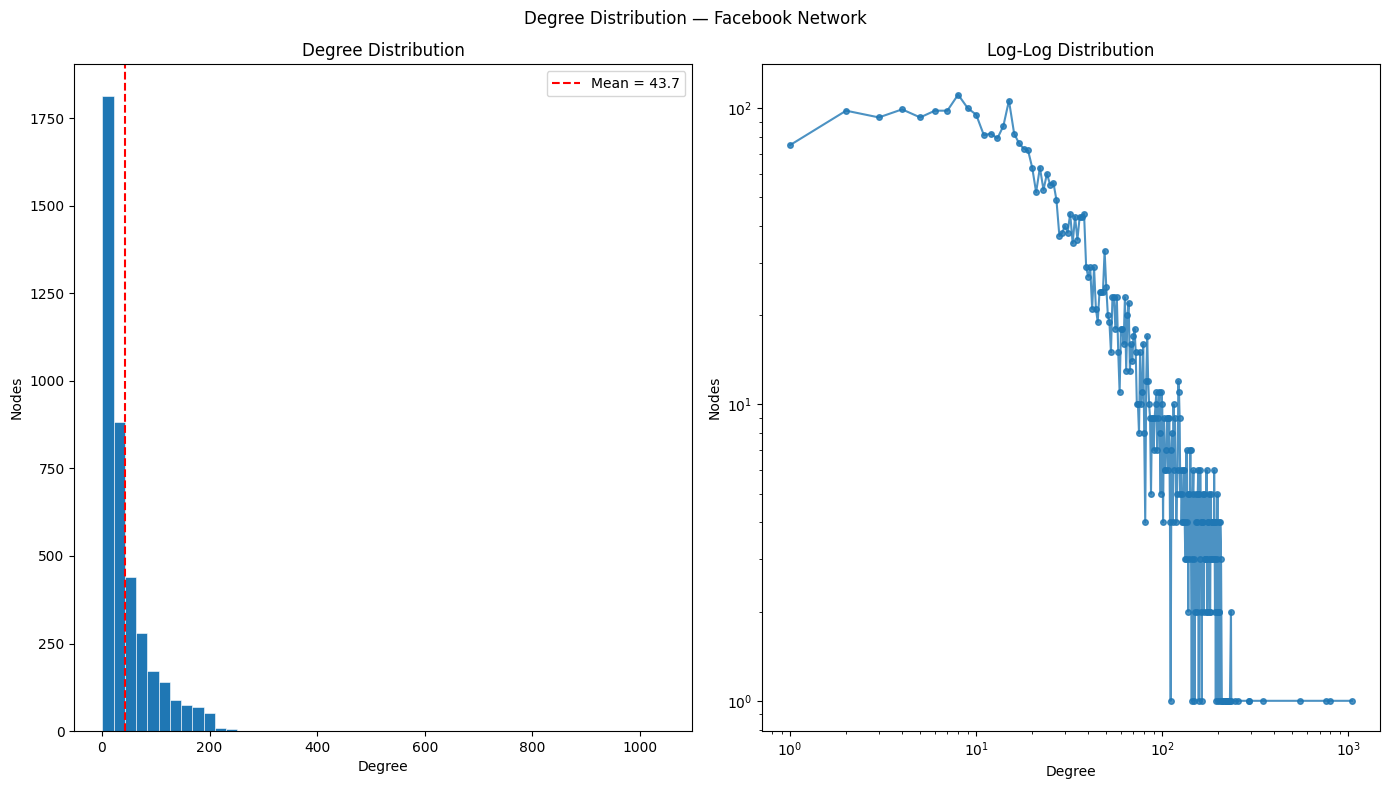

Degree stats:
count    4039.00
mean       43.69
std        52.42
min         1.00
25%        11.00
50%        25.00
75%        57.00
max      1045.00
dtype: float64


In [43]:
"""
Visualise degree distribution of the network:
- Histogram (linear scale)
- Log-log plot to check heavy-tailed behaviour
"""

# Unique degree values and their frequencies
values = sorted(set(deg_vals))
hist = [deg_vals.count(x) for x in values]

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(14, 8))


# Linear scale histogram
axes[0].hist(deg_vals, bins=50, edgecolor='white', linewidth=0.4)
axes[0].axvline(avg_deg, color='red', linestyle='--', label=f'Mean = {avg_deg:.1f}')  # average degree
axes[0].set_xlabel('Degree')
axes[0].set_ylabel('Nodes')
axes[0].set_title('Degree Distribution')
axes[0].legend()

# Log-log plot (reveals power-law / scale-free patterns)
axes[1].loglog(values, hist, 'o-', markersize=4, alpha=0.8)
axes[1].set_xlabel('Degree')
axes[1].set_ylabel('Nodes')
axes[1].set_title('Log-Log Distribution')

# Final formatting
plt.suptitle('Degree Distribution — Facebook Network')
plt.tight_layout() # Adjust layout
plt.show() # Display plot

# Summary statistics of degree distribution
print('Degree stats:')
print(pd.Series(deg_vals).describe().round(2))

###
**Node Centrality Measures**

In [5]:
"""
Compute centrality measures to identify important nodes:
- Degree: most connected nodes
- Closeness: nodes closest to others
- Betweenness: nodes acting as bridges
- Eigenvector: influence based on neighbours
- PageRank: importance based on link structure
"""

# Helper function to print top 5 nodes
def top5_nodes(centrality, name):
    top5 = sorted(centrality.items(), key=lambda x: x[1], reverse=True)[:5]
    print(f'\nTop 5 nodes by {name}:')
    for node, val in top5:
        print(f'Node {node}: {val:.6f}')


# Centrality calculations
degree_centrality = nx.degree_centrality(G) # direct connections
closeness_centrality = nx.closeness_centrality(G) # distance to others
betweenness_centrality = nx.betweenness_centrality(G, k=200, seed=RANDOM_STATE) # bridge nodes (approx)
eigenvector_centrality = nx.eigenvector_centrality(G, max_iter=1000) # influence via neighbours
pagerank = nx.pagerank(G, alpha=0.8) # importance via links


# Display top 5 nodes for each metric
top5_nodes(degree_centrality, 'Degree Centrality')
top5_nodes(closeness_centrality, 'Closeness Centrality')
top5_nodes(betweenness_centrality, 'Betweenness Centrality')
top5_nodes(eigenvector_centrality, 'Eigenvector Centrality')
top5_nodes(pagerank, 'PageRank')


Top 5 nodes by Degree Centrality:
Node 107: 0.258791
Node 1684: 0.196137
Node 1912: 0.186974
Node 3437: 0.135463
Node 0: 0.085934

Top 5 nodes by Closeness Centrality:
Node 107: 0.459699
Node 58: 0.397402
Node 428: 0.394837
Node 563: 0.393913
Node 1684: 0.393606

Top 5 nodes by Betweenness Centrality:
Node 107: 0.490797
Node 1684: 0.360785
Node 1912: 0.226178
Node 3437: 0.214301
Node 0: 0.147413

Top 5 nodes by Eigenvector Centrality:
Node 1912: 0.095407
Node 2266: 0.086983
Node 2206: 0.086052
Node 2233: 0.085173
Node 2464: 0.084279

Top 5 nodes by PageRank:
Node 3437: 0.007585
Node 107: 0.007062
Node 1684: 0.006402
Node 0: 0.006374
Node 1912: 0.003960


###
**Network Visualisation**

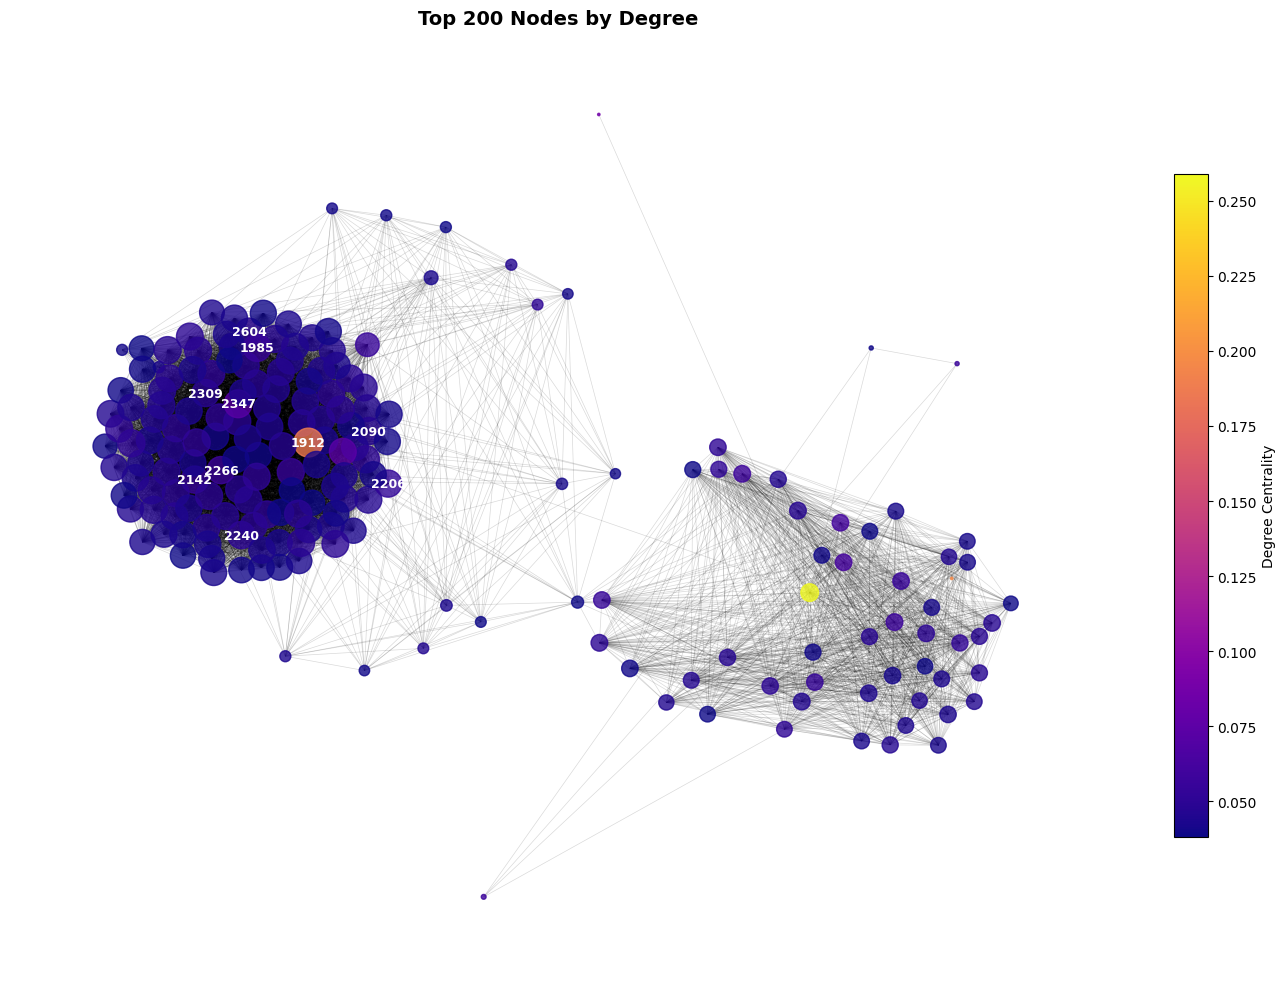

In [44]:
# Select top 200 nodes by degree
top200 = sorted(G.degree(), key=lambda x: x[1], reverse=True)[:200]
G_sub  = G.subgraph([n for n, _ in top200])

# Compute layout (spring layout for visual separation)
pos = nx.spring_layout(G_sub, seed=RANDOM_STATE, k=1.0) # k controls the spacing between nodes

# Node styling
node_sizes  = [G_sub.degree(n) * 3 for n in G_sub.nodes()] # larger = more connections
node_colors = [degree_centrality[n] for n in G_sub.nodes()] # colour = centrality

# Create figure
plt.figure(figsize=(14, 10))

# Draw nodes
nx.draw_networkx_nodes(G_sub, pos,
                       node_size=node_sizes,
                       node_color=node_colors,
                       cmap='plasma',
                       alpha=0.8)

# Draw edges for more clarity
nx.draw_networkx_edges(G_sub, pos, alpha=0.15, width=0.5)

# Label only top 10 nodes by degree centrality to avoid overcrowding
top10_ids = [n for n, _ in sorted(G_sub.degree(),
                                   key=lambda x: x[1],
                                   reverse=True)[:10]
            if n in G_sub.nodes()]
nx.draw_networkx_labels(G_sub, pos,
                        labels={n: str(n) for n in top10_ids},
                        font_size=9,
                        font_color='white',
                        font_weight='bold')


# Add colour bar for centrality scale
sm = plt.cm.ScalarMappable(
    cmap='plasma',
    norm=plt.Normalize(min(node_colors), max(node_colors))
)
sm.set_array([])
plt.colorbar(sm, ax=plt.gca(), label='Degree Centrality', shrink=0.7)


# Final formatting
plt.title('Top 200 Nodes by Degree', fontsize=14, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

##
## Task 2: Edge Betweenness Centrality
Edge betweenness centrality measures the fraction of shortest paths passing through each edge; high values indicate bridge edges between communities. k=1000 approximation is used for accuracy on 88,234 edges.

In [8]:
"""
Compute edge betweenness centrality:
- Measures how often edges lie on shortest paths
- Uses k=1000 node sampling for a more accurate approximation
"""

# Calculate edge betweenness centrality (approximate)
edge_bc = nx.edge_betweenness_centrality(G, k=1000, seed=RANDOM_STATE)

# Extract values for analysis
bc_values = list(edge_bc.values())
bc_series = pd.Series(bc_values)


# Display summary
print(f'Edge BC computed for {len(bc_values):,} edges.')
print(f'\nDescriptive statistics:')
print(bc_series.describe().to_string())

Edge BC computed for 88,234 edges.

Descriptive statistics:
count    8.823400e+04
mean     1.033702e-05
std      2.726379e-04
min      0.000000e+00
25%      6.744240e-08
50%      1.827911e-07
75%      6.199452e-07
max      4.362106e-02


###
**Distribution Plots**

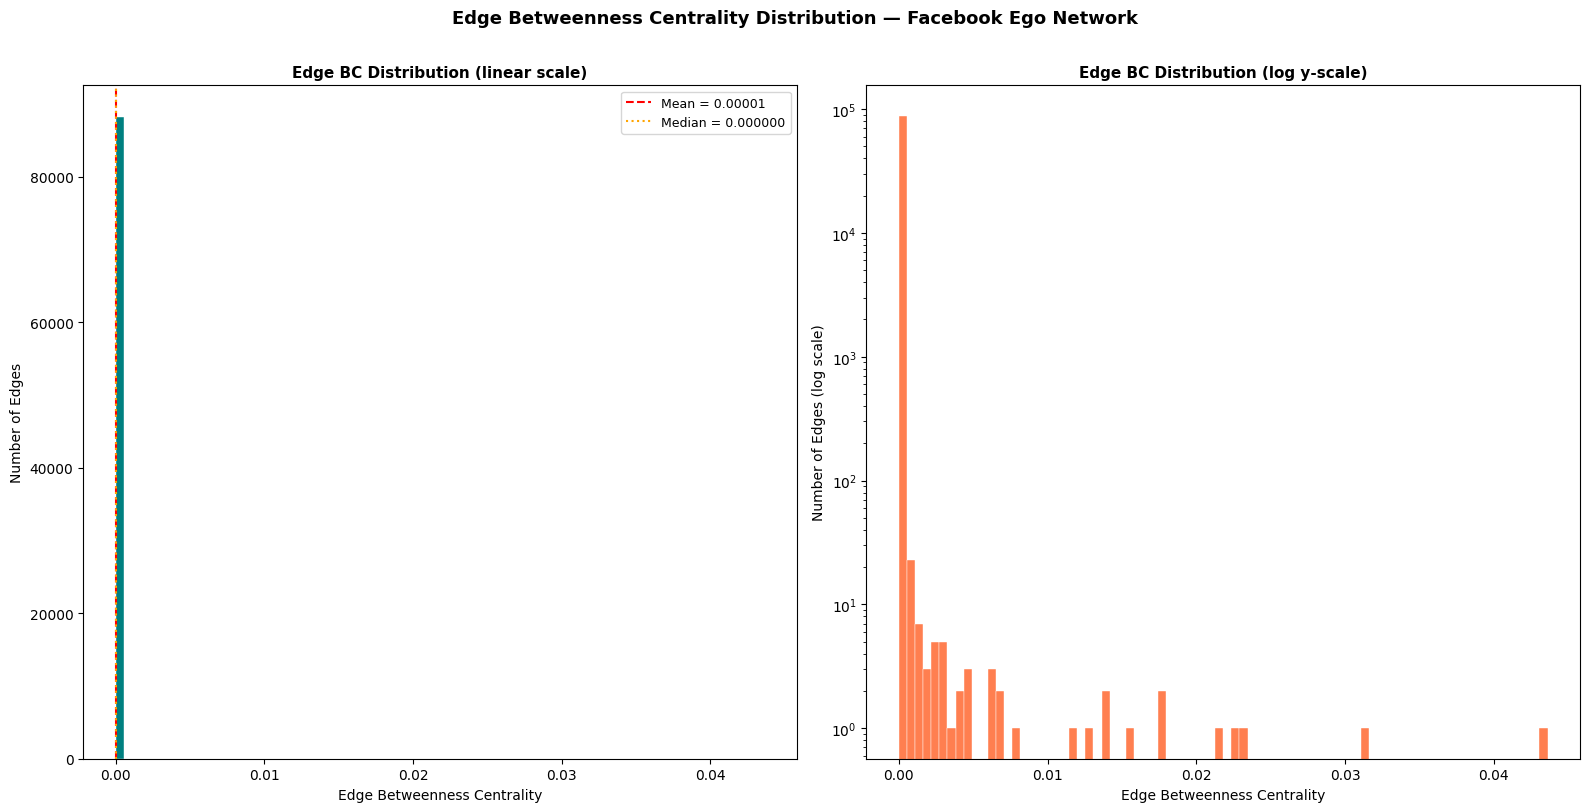

In [46]:
# Visualise edge betweenness centrality distribution

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Linear scale histogram
axes[0].hist(bc_series, bins=80, color='teal', edgecolor='white', linewidth=0.3)

# Mean and median reference lines
axes[0].axvline(bc_series.mean(), color='red', linestyle='--', label=f'Mean = {bc_series.mean():.5f}')
axes[0].axvline(bc_series.median(), color='orange', linestyle=':', label=f'Median = {bc_series.median():.6f}')

axes[0].set_xlabel('Edge Betweenness Centrality')
axes[0].set_ylabel('Number of Edges')
axes[0].set_title('Edge BC Distribution (linear scale)', fontsize=11, fontweight='bold')
axes[0].legend(fontsize=9)


# Log y-scale histogram (reveals heavy-tailed behaviour)
axes[1].hist(bc_series, bins=80, color='coral', edgecolor='white', linewidth=0.3)
axes[1].set_yscale('log')

axes[1].set_xlabel('Edge Betweenness Centrality')
axes[1].set_ylabel('Number of Edges (log scale)')
axes[1].set_title('Edge BC Distribution (log y-scale)', fontsize=11, fontweight='bold')

# Final formatting
plt.suptitle('Edge Betweenness Centrality Distribution — Facebook Ego Network',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

###
**Top Bridge Edges**

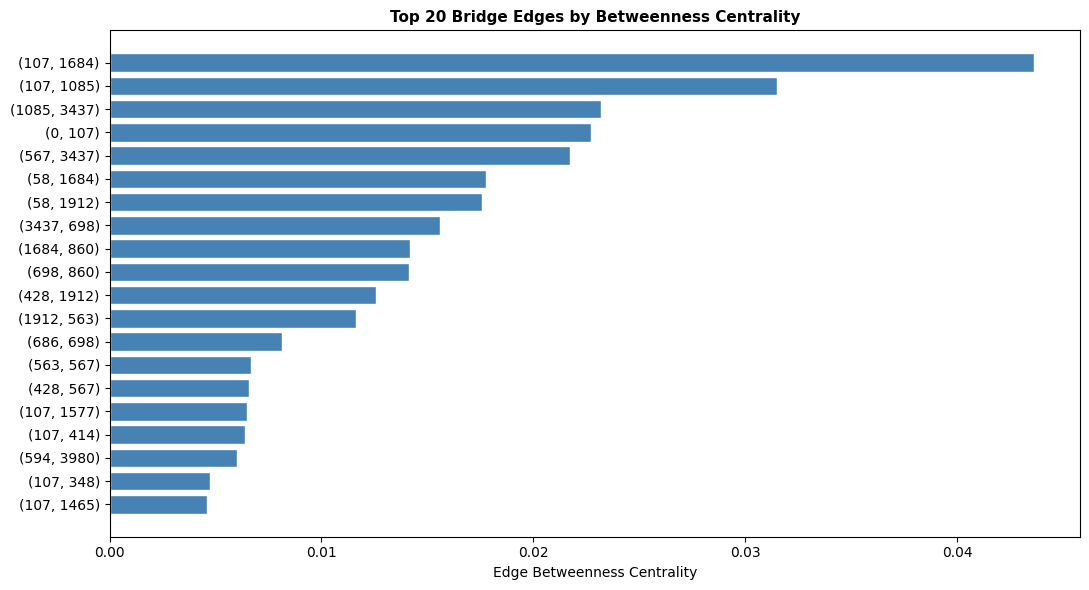

Top 10 bridge edges:
        Edge  Betweenness Centrality
 (107, 1684)                0.043621
 (107, 1085)                0.031524
(1085, 3437)                0.023207
    (0, 107)                0.022732
 (567, 3437)                0.021709
  (58, 1684)                0.017755
  (58, 1912)                0.017599
 (3437, 698)                0.015618
 (1684, 860)                0.014174
  (698, 860)                0.014134


In [47]:
# Identify and visualise top bridge edges

# Select top 20 edges by betweenness centrality
top_edges = sorted(edge_bc.items(), key=lambda x: x[1], reverse=True)[:20]

# Convert to DataFrame for plotting
top_edge_df = pd.DataFrame(top_edges, columns=['Edge', 'Betweenness Centrality'])
top_edge_df['Edge'] = top_edge_df['Edge'].astype(str)


# Horizontal bar chart (largest at top)
plt.figure(figsize=(11, 6))
plt.barh(top_edge_df['Edge'][::-1], top_edge_df['Betweenness Centrality'][::-1], color='steelblue', edgecolor='white')

plt.xlabel('Edge Betweenness Centrality')
plt.title('Top 20 Bridge Edges by Betweenness Centrality', fontsize=11, fontweight='bold')

# Adjust layout and display plot
plt.tight_layout()
plt.show()

# Display top 10 edges
print('Top 10 bridge edges:')
print(top_edge_df.head(10).to_string(index=False))

##
## Task 3: Community Detection - Three Algorithms
Three algorithms are applied:
- **Girvan-Newman** - edge removal on top-100-node subgraph
- **Louvain** - modularity optimisation on full graph (best practice for large networks)
- **Label Propagation** - structural propagation on full graph

Each algorithm is evaluated on number of communities, average community size, and modularity Q.

###
**Algorithm 1: Girvan-Newman**

In [11]:
# Build subgraph of top 100 nodes by degree
top100 = sorted(G.degree(), key=lambda x: x[1], reverse=True)[:100]
G_gn   = G.subgraph([n for n, _ in top100]).copy()
print(f'Girvan-Newman subgraph: {G_gn.number_of_nodes()} nodes, '
      f'{G_gn.number_of_edges()} edges')

# Generate community splits
gn_gen    = girvan_newman(G_gn)
gn_best_mod   = -1 # track best modularity score
gn_best_comms = None # store best partition

# Evaluate first 10 splits and keep the best one
for step, comms in enumerate(gn_gen):
    comms_list = list(comms)
    try:
        q = modularity(G_gn, comms_list) # quality partition
        if q > gn_best_mod:
            gn_best_mod   = q
            gn_best_comms = comms_list
    except:
        pass
    if step >= 9:
        break

# Community size statistics
gn_sizes = sorted([len(c) for c in gn_best_comms], reverse=True)
gn_avg_size = sum(gn_sizes) / len(gn_sizes)

# Display Results
print('\nGirvan-Newman results:')
print(f'Communities: {len(gn_best_comms)}')
print(f'Modularity: {gn_best_mod:.4f}')
print(f'Avg size: {gn_avg_size:.1f}')
print(f'Sizes: {gn_sizes}')

Girvan-Newman subgraph: 100 nodes, 2422 edges

Girvan-Newman results:
Communities: 4
Modularity: 0.2457
Avg size: 25.0
Sizes: [68, 30, 1, 1]


###
**Algorithm 2:  Louvain**

In [12]:
# Detect communities (node: community id)
partition = community_louvain.best_partition(G, random_state=RANDOM_STATE)

# Group nodes by community
comm_dict = collections.defaultdict(list)
for node, cid in partition.items():
    comm_dict[cid].append(node)

# Convert community lists to frozensets
louv_comms = [frozenset(nodes) for nodes in comm_dict.values()]

# Build community_map for visualisation
community_map_louv = {node: cid for node, cid in partition.items()}

# Compute statistics
louv_n_comms = len(louv_comms) # number of communities
louv_mod = modularity(G, louv_comms) # modularity score
louv_sizes = sorted([len(c) for c in louv_comms], reverse=True)
louv_avg_size = sum(louv_sizes) / louv_n_comms # average community size

# Display results
print('\nLouvain results:')
print(f'Communities: {louv_n_comms}')
print(f'Modularity: {louv_mod:.4f}')
print(f'Avg size: {louv_avg_size:.1f}')
print(f'Sizes: {louv_sizes}')


Louvain results:
Communities: 15
Modularity: 0.8349
Avg size: 269.3
Sizes: [548, 535, 442, 432, 430, 354, 323, 237, 226, 206, 128, 73, 61, 25, 19]


###
**Algorithm 3: Label Propagation**

In [14]:
# Detect communities
lpa_comms = list(label_propagation_communities(G))

# Map nodes to community IDs
community_map_lpa = {}
for i, comm in enumerate(lpa_comms):
    for node in comm:
        community_map_lpa[node] = i

# Compute statistics
lpa_n_comms = len(lpa_comms) # number of communities
lpa_mod = modularity(G, lpa_comms) # modularity score
lpa_sizes = sorted([len(c) for c in lpa_comms], reverse=True)
lpa_avg_size = sum(lpa_sizes) / lpa_n_comms # average community size

# Display results
print('\nLabel Propagation results:')
print(f'Communities: {lpa_n_comms}')
print(f'Modularity: {lpa_mod:.4f}')
print(f'Avg size: {lpa_avg_size:.1f}')
print(f'Top 5 sizes: {lpa_sizes[:5]}')


Label Propagation results:
Communities: 44
Modularity: 0.7368
Avg size: 91.8
Top 5 sizes: [1030, 753, 547, 469, 226]


###
**Algorithm Comparison**

In [16]:
# Compare community detection algorithms

print('Community Detection Comparison\n')

# Display key metrics for each method
print(f'Girvan-Newman(subgraph): {len(gn_best_comms)} communities ; Q={gn_best_mod:.4f} ; avg size={gn_avg_size:.1f}')
print(f'Louvain(full): {louv_n_comms} communities ; Q={louv_mod:.4f} ; avg size={louv_avg_size:.1f}')
print(f'Label Propagation(full): {lpa_n_comms} communities ; Q={lpa_mod:.4f} ; avg size={lpa_avg_size:.1f}')

Community Detection Comparison

Girvan-Newman(subgraph): 4 communities ; Q=0.2457 ; avg size=25.0
Louvain(full): 15 communities ; Q=0.8349 ; avg size=269.3
Label Propagation(full): 44 communities ; Q=0.7368 ; avg size=91.8


###
**Visualise Girvan-Newman communities (top 100 nodes)**

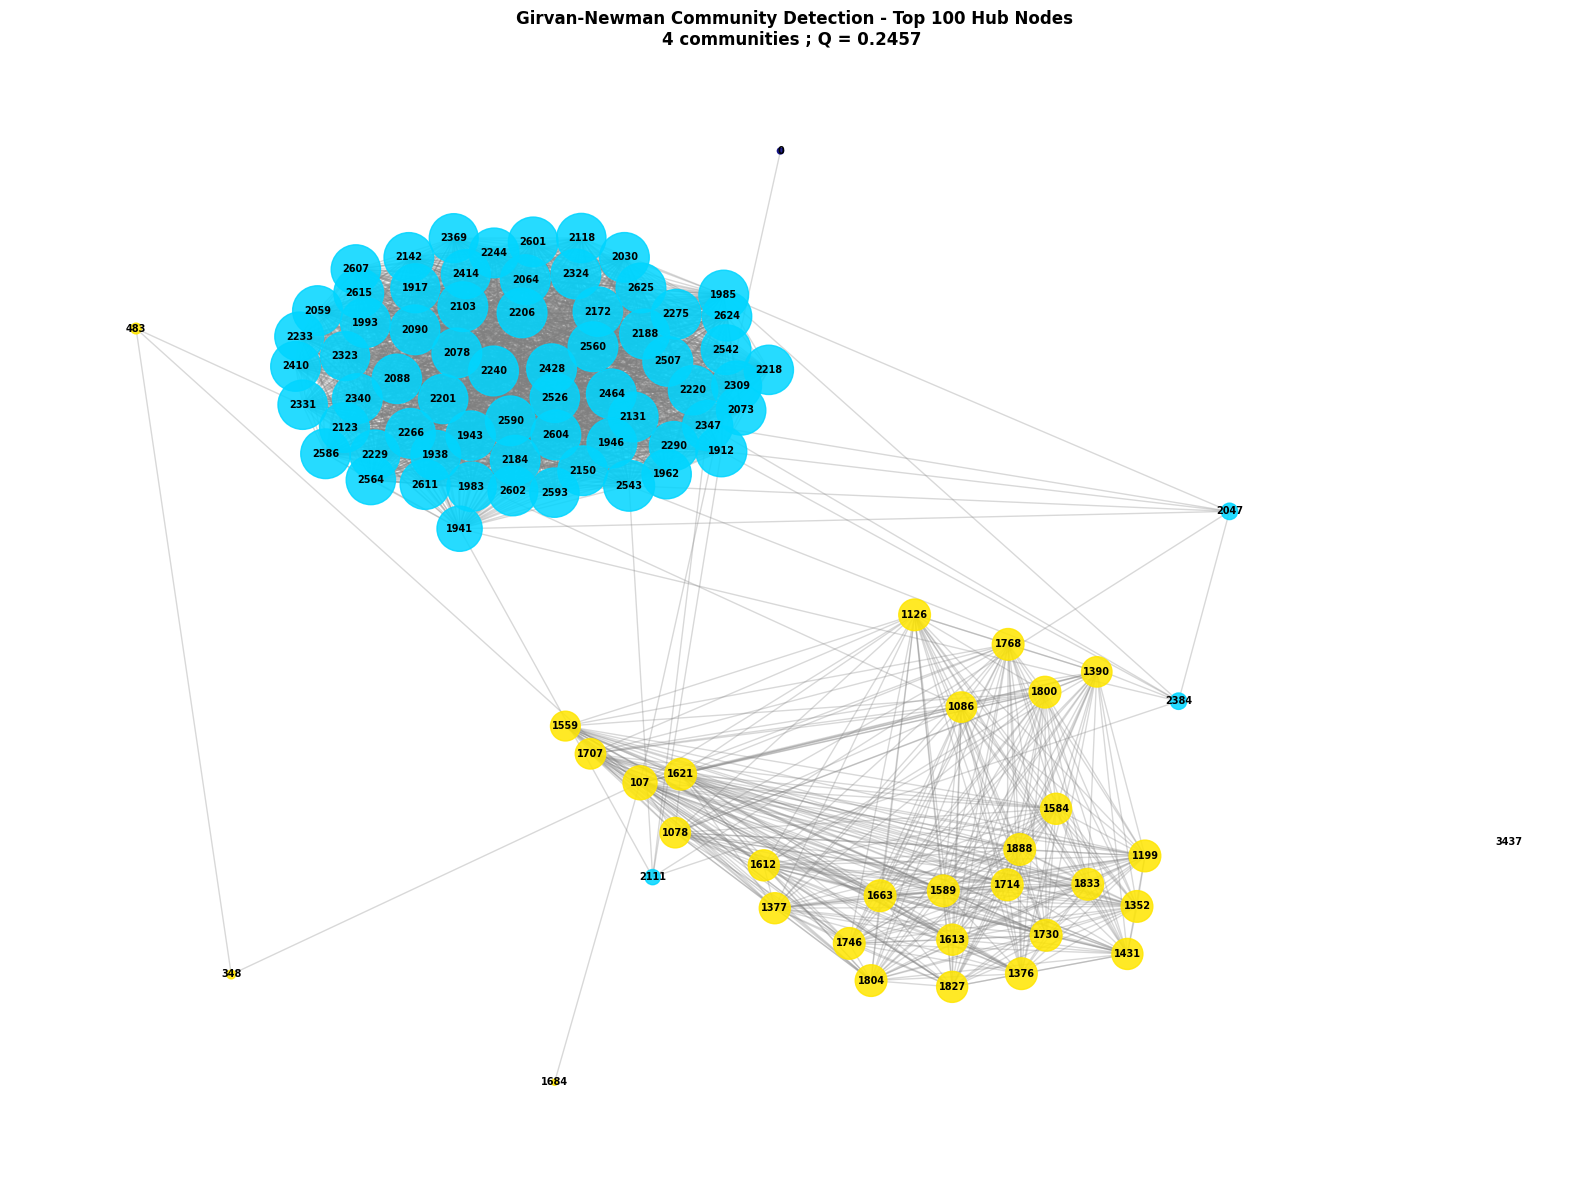

In [48]:
# Build community map
community_map_gn = {}
for i, community in enumerate(gn_best_comms):
    for node in community:
        community_map_gn[node] = i


# Layout and styling
pos_gn = nx.spring_layout(G_gn, seed=RANDOM_STATE, k=1.0) # k controls the spacing between nodes 
colors_gn = [community_map_gn.get(n, 0) for n in G_gn.nodes()] # colour by community
sizes_gn = [G_gn.degree(n) * 8 for n in G_gn.nodes()] # size by degree


# Plot graph
plt.figure(figsize=(16, 12))

nx.draw_networkx_nodes(G_gn, pos_gn,
                       node_color=colors_gn,
                       cmap=plt.cm.jet,
                       node_size=[G_gn.degree(n) * 20 for n in G_gn.nodes()],
                       alpha=0.85)

nx.draw_networkx_edges(G_gn, pos_gn,
                       alpha=0.3, width=1.0, 
                       edge_color='grey')

# Add node labels for the top 100 hub nodes
nx.draw_networkx_labels(G_gn, pos_gn,
                        font_size=7,
                        font_color='black',
                        font_weight='bold')


# Title and formatting
plt.title(
    f'Girvan-Newman Community Detection - Top 100 Hub Nodes\n'
    f'{len(gn_best_comms)} communities ; Q = {gn_best_mod:.4f} ',
    fontsize=12, fontweight='bold'
)

plt.axis('off')
plt.tight_layout()
plt.show()

###
**Visualise Louvain Communities**

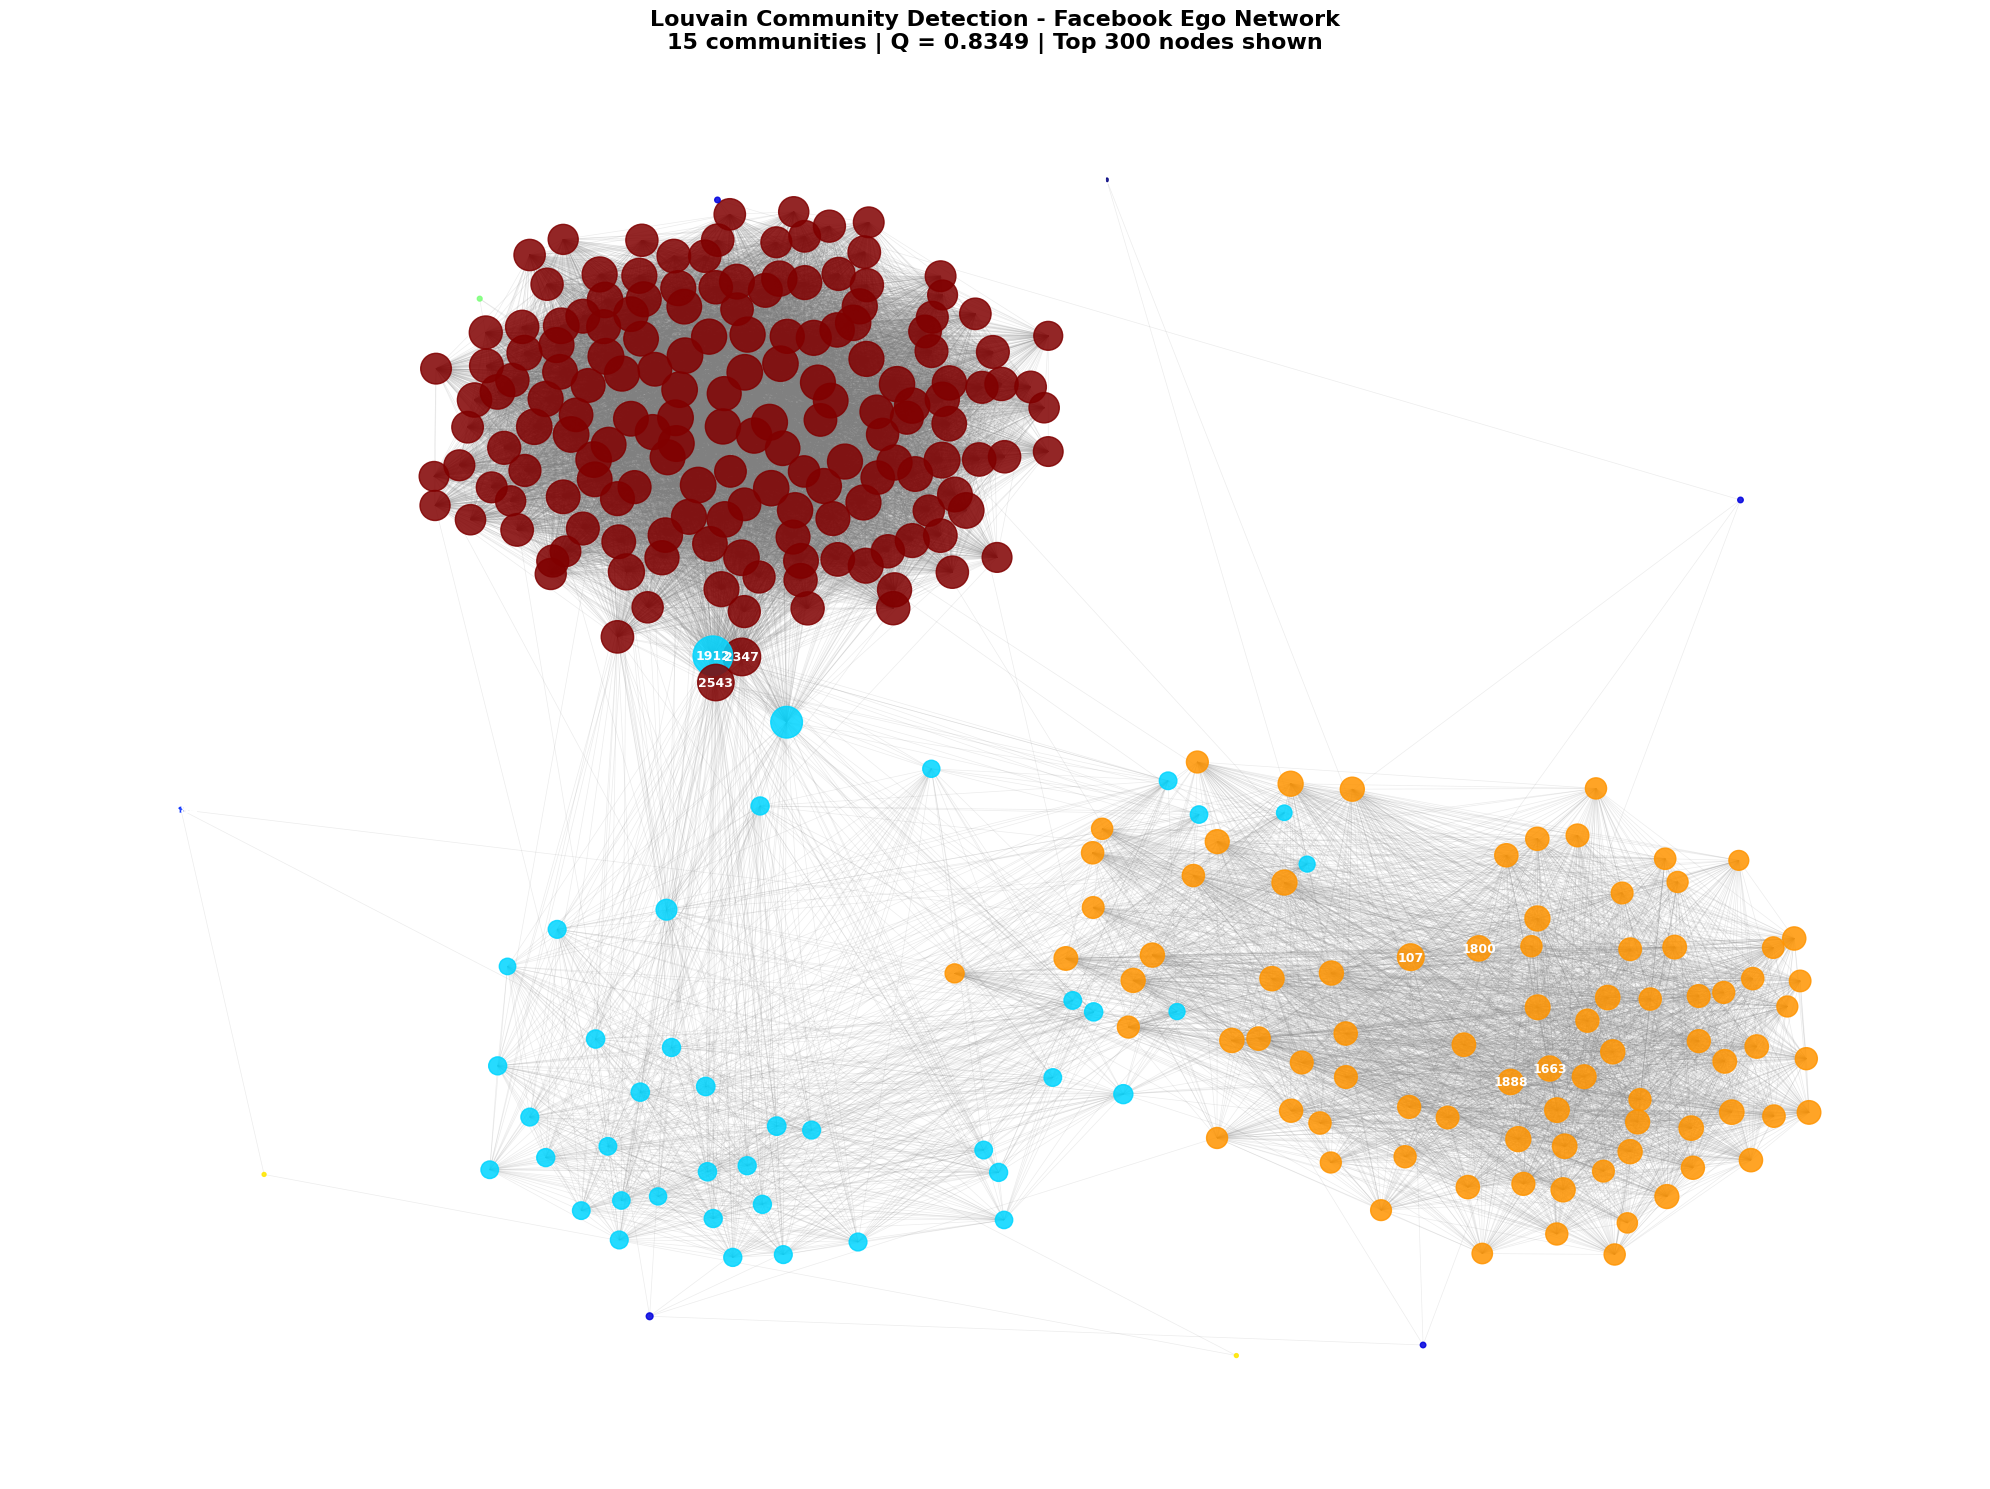

In [49]:
# Visualise Louvain communities (top 300 nodes)

# Select top 300 nodes by degree
top300_ids = [n for n, _ in sorted(G.degree(), key=lambda x: x[1], reverse=True)[:300]]
G_vis = G.subgraph(top300_ids)

# Layout
pos = nx.spring_layout(G_vis, seed=RANDOM_STATE, k=1.0) # k controls the spacing between nodes

# Node styling
colors_louv = [community_map_louv.get(n, 0) for n in G_vis.nodes()] # colour by community
node_sizes  = [G_vis.degree(n) * 4 for n in G_vis.nodes()] # size by degree

# Plot graph
plt.figure(figsize=(20, 15))

nx.draw_networkx_nodes(G_vis, pos,
                       node_color=colors_louv,
                       cmap=plt.cm.jet,
                       node_size=node_sizes,
                       alpha=0.85)

nx.draw_networkx_edges(G_vis, pos,
                       alpha=0.15, width=0.5, 
                       edge_color='grey')


# Label top 10 nodes by degree centrality
top10_ids = [n for n, _ in sorted(degree_centrality.items(),
                                   key=lambda x: x[1], reverse=True)[:10]
             if n in G_vis.nodes()]

nx.draw_networkx_labels(
    G_vis, pos,
    labels={n: str(n) for n in top10_ids},
    font_size=9, font_color='white', font_weight='bold'
)

# Title and formatting
plt.title(
    f'Louvain Community Detection - Facebook Ego Network\n'
    f'{louv_n_comms} communities | Q = {louv_mod:.4f} | Top 300 nodes shown',
    fontsize=16, fontweight='bold'
)
plt.axis('off')
plt.tight_layout()
plt.show()

###
**Visualise Label Propagation Communities**

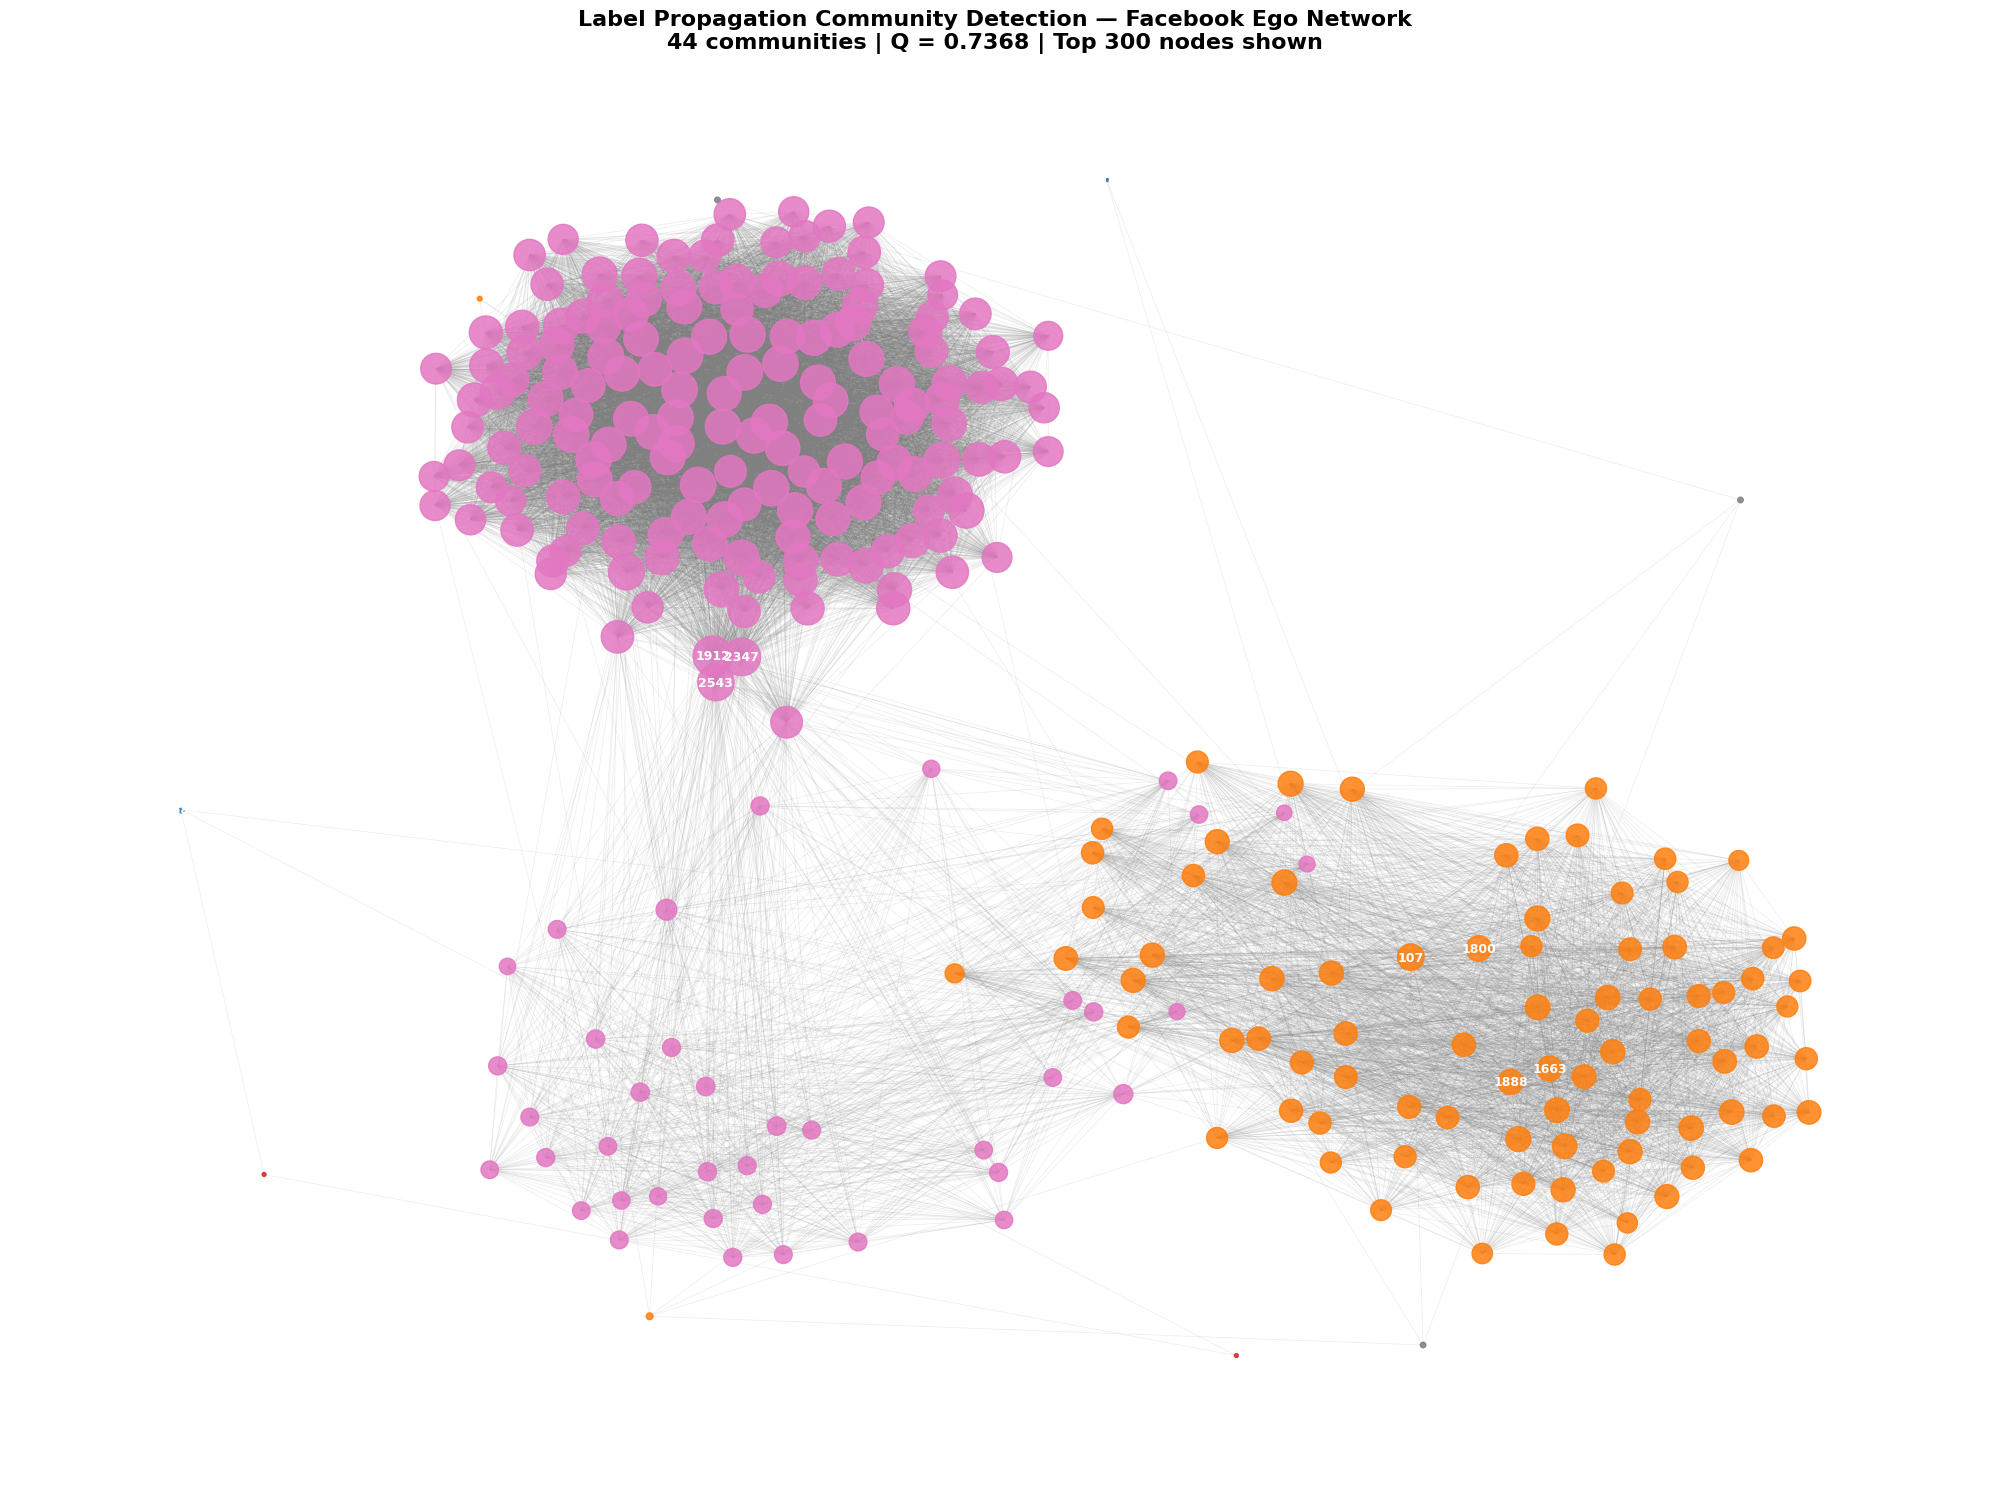

In [50]:
# Visualise Label Propagation communities (top 300 nodes)
plt.figure(figsize=(20, 15))

# Draw each community with a distinct colour
for j, community in enumerate(lpa_comms):
    nodelist = [n for n in community if n in G_vis.nodes()]
    if nodelist:
        nx.draw_networkx_nodes(G_vis, pos,
                               nodelist=nodelist,
                               node_color=f'C{j % 20}', # cycle colours
                               node_size=[G_vis.degree(n) * 4 for n in nodelist],
                               alpha=0.85)


# Draw edges
nx.draw_networkx_edges(G_vis, pos,
                       alpha=0.15, width=0.5, edge_color='grey')


# Label top 10 nodes by degree centrality
nx.draw_networkx_labels(G_vis, pos,
                        labels={n: str(n) for n in top10_ids},
                        font_size=9, font_color='white', font_weight='bold')


# Title and formatting
plt.title(
    f'Label Propagation Community Detection — Facebook Ego Network\n'
    f'{lpa_n_comms} communities | Q = {lpa_mod:.4f} | Top 300 nodes shown',
    fontsize=16, fontweight='bold'
)
plt.axis('off')
plt.tight_layout()
plt.show()

###
**Community Size Distribution Comparison**

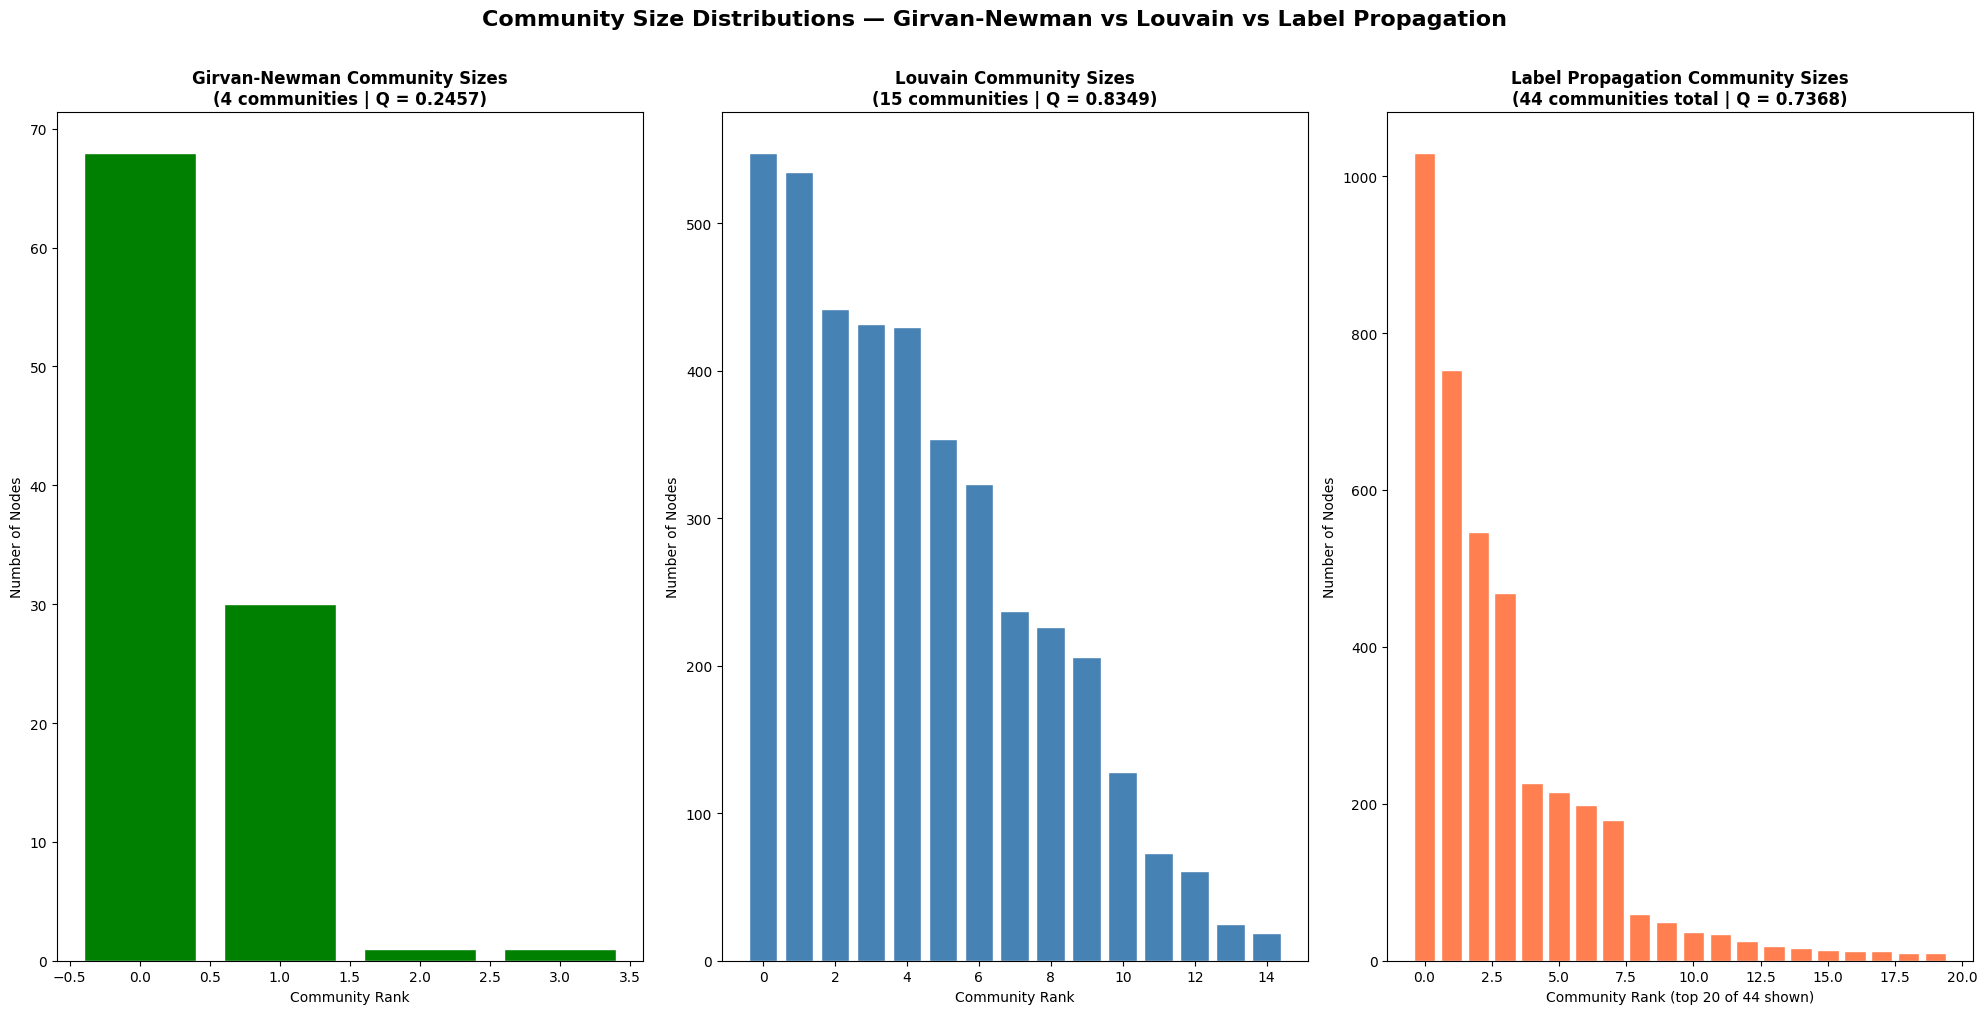

In [51]:
# Compare community size distributions: Girvan-Newman, Louvain, Label Propagation

fig, axes = plt.subplots(1, 3, figsize=(20, 10))


# Girvan-Newman community sizes
axes[0].bar(range(len(gn_sizes)), gn_sizes,
            color='green', edgecolor='white')
axes[0].set_xlabel('Community Rank')
axes[0].set_ylabel('Number of Nodes')
axes[0].set_title(
    f'Girvan-Newman Community Sizes\n'
    f'({len(gn_sizes)} communities | Q = {gn_best_mod:.4f})',
    fontsize=12, fontweight='bold'
)

# Louvain community sizes
axes[1].bar(range(louv_n_comms), louv_sizes,
            color='steelblue', edgecolor='white')
axes[1].set_xlabel('Community Rank')
axes[1].set_ylabel('Number of Nodes')
axes[1].set_title(
    f'Louvain Community Sizes\n'
    f'({louv_n_comms} communities | Q = {louv_mod:.4f})',
    fontsize=12, fontweight='bold'
)

# Label Propagation community sizes (top 20 only for readability)
show_n = min(20, lpa_n_comms)
axes[2].bar(range(show_n), lpa_sizes[:show_n],
            color='coral', edgecolor='white')
axes[2].set_xlabel(f'Community Rank (top {show_n} of {lpa_n_comms} shown)')
axes[2].set_ylabel('Number of Nodes')
axes[2].set_title(
    f'Label Propagation Community Sizes\n'
    f'({lpa_n_comms} communities total | Q = {lpa_mod:.4f})',
    fontsize=12, fontweight='bold'
)


# Final formatting and display plot
plt.suptitle(
    'Community Size Distributions — Girvan-Newman vs Louvain vs Label Propagation',
    fontsize=16, fontweight='bold', y=1.01
)
plt.tight_layout()
plt.show()

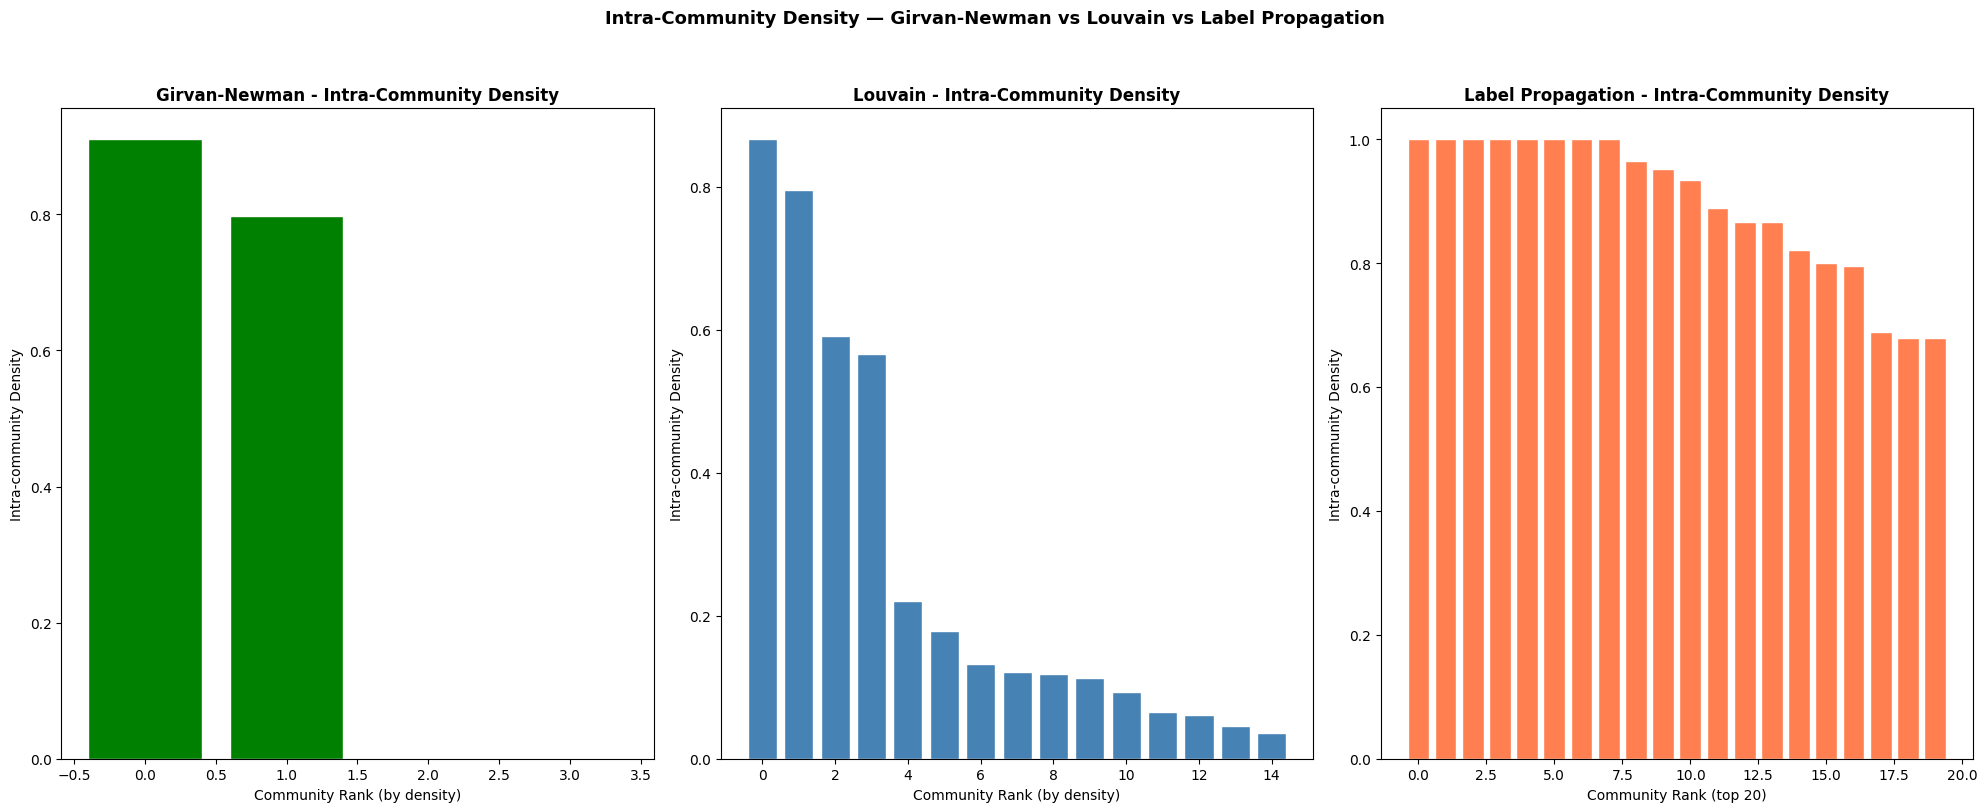

Girvan-Newman intra-community density:
count    4.0000
mean     0.4270
std      0.4952
min      0.0000
25%      0.0000
50%      0.3989
75%      0.8259
max      0.9104
dtype: float64

Louvain intra-community density:
count    15.0000
mean      0.2670
std       0.2858
min       0.0357
25%       0.0799
50%       0.1209
75%       0.3929
max       0.8667
dtype: float64

Label Propagation intra-community density:
count    44.0000
mean      0.6134
std       0.3262
min       0.0356
25%       0.3550
50%       0.6667
75%       0.9000
max       1.0000
dtype: float64


In [52]:
"""
Compare intra-community density:
- Measures how tightly connected each community is
- Higher density = stronger internal connectivity
"""

# Compute density for each community
def intra_density(G, communities):
    # Density of each community subgraph
    return pd.Series(sorted(
        [nx.density(G.subgraph(c)) for c in communities],
        reverse=True
    ))

# Apply to all three methods
gn_dens = intra_density(G_gn, gn_best_comms) # GN uses subgraph
louv_dens = intra_density(G, louv_comms)
lpa_dens = intra_density(G, lpa_comms)

# Plot results
fig, axes = plt.subplots(1, 3, figsize=(20, 8))

# Girvan-Newman
axes[0].bar(range(len(gn_dens)), gn_dens,
            color='green', edgecolor='white')
axes[0].set_xlabel('Community Rank (by density)')
axes[0].set_ylabel('Intra-community Density')
axes[0].set_title('Girvan-Newman - Intra-Community Density',
                  fontsize=12, fontweight='bold')

# Louvain
axes[1].bar(range(len(louv_dens)), louv_dens,
            color='steelblue', edgecolor='white')
axes[1].set_xlabel('Community Rank (by density)')
axes[1].set_ylabel('Intra-community Density')
axes[1].set_title('Louvain - Intra-Community Density',
                  fontsize=12, fontweight='bold')

# Label Propagation (top 20 only for readability)
axes[2].bar(range(min(20, len(lpa_dens))), lpa_dens[:20],
            color='coral', edgecolor='white')
axes[2].set_xlabel('Community Rank (top 20)')
axes[2].set_ylabel('Intra-community Density')
axes[2].set_title('Label Propagation - Intra-Community Density',
                  fontsize=12, fontweight='bold')

# Final formatting
plt.suptitle('Intra-Community Density — Girvan-Newman vs Louvain vs Label Propagation\n',
             fontsize=13, fontweight='bold', y=1.01)

# Adjust layout and display plot
plt.tight_layout()
plt.show()


# Summary statistics
print('Girvan-Newman intra-community density:')
print(gn_dens.describe().round(4))

print('\nLouvain intra-community density:')
print(louv_dens.describe().round(4))

print('\nLabel Propagation intra-community density:')
print(lpa_dens.describe().round(4))